 Colonnes détectées : Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

 Répartition des clusters :
Cluster
 0    679
-1     14
 1      6
Name: count, dtype: int64


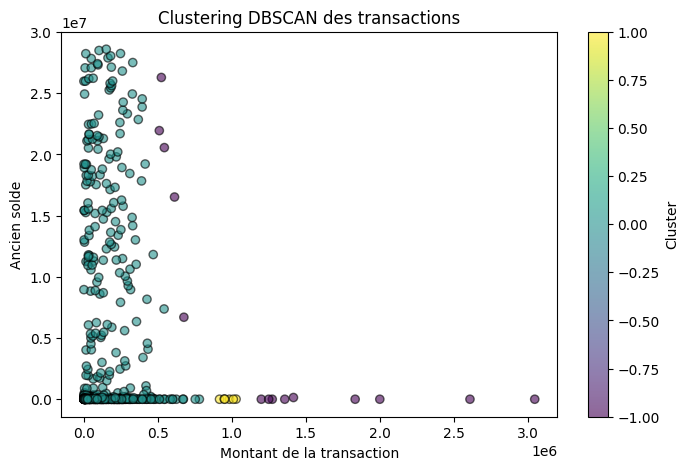


 Transactions suspectes détectées :
         amount  oldbalanceOrg  Cluster
51    612854.02    16524483.72       -1
79    544113.07    20562707.54       -1
90    510107.98    21950297.65       -1
113   523838.21    26293880.96       -1
325  1199061.38           0.00       -1
326  1833231.66           0.00       -1
346  1999821.13           0.00       -1
368  1416381.43      139113.00       -1
522   676068.78     6699701.50       -1
607  3046586.66           0.00       -1
611  1273234.79           0.00       -1
614  2608986.72           0.00       -1
616  1249294.17           0.00       -1
646  1357657.78           0.00       -1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

file_path = "./data/transactions_fixed.csv"
df = pd.read_csv(file_path, sep=';')

# Vérification des colonnes existantes
print(f" Colonnes détectées : {df.columns}")

colonnes_utiles = ['amount', 'oldbalanceOrg']
colonnes_manquantes = [col for col in colonnes_utiles if col not in df.columns]

if colonnes_manquantes:
    print(f" Colonnes absentes : {colonnes_manquantes}")
else:
    # Sélection des colonnes utiles et suppression des valeurs NaN
    df_selected = df[colonnes_utiles].dropna()

    # Conversion en numérique
    df_selected = df_selected.apply(pd.to_numeric, errors='coerce').dropna()

    # Normalisation des données
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_selected)

    # Application de DBSCAN
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    clusters = dbscan.fit_predict(X_scaled)

    # Ajout des clusters au DataFrame
    df_selected['Cluster'] = clusters

    # Affichage des clusters
    print("\n Répartition des clusters :")
    print(df_selected['Cluster'].value_counts())

    # Visualisation des clusters
    plt.figure(figsize=(8, 5))
    plt.scatter(df_selected['amount'], df_selected['oldbalanceOrg'], c=df_selected['Cluster'], cmap='viridis', alpha=0.6, edgecolors='k')
    plt.xlabel('Montant de la transaction')
    plt.ylabel('Ancien solde')
    plt.title('Clustering DBSCAN des transactions')
    plt.colorbar(label='Cluster')
    plt.show()

    # Affichage des anomalies (Cluster = -1)
    anomalies = df_selected[df_selected['Cluster'] == -1]
    print("\n Transactions suspectes détectées :")
    print(anomalies)

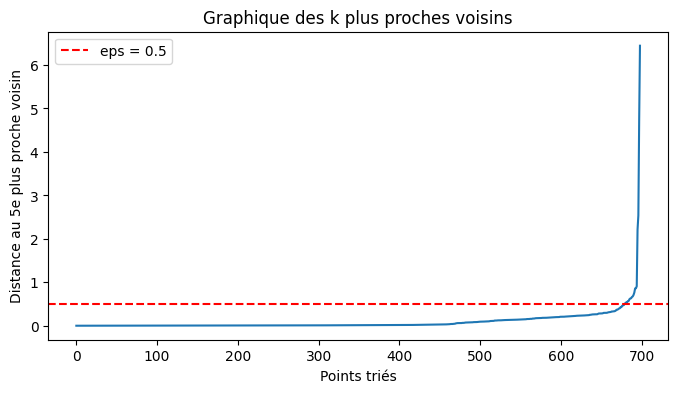

In [2]:
from sklearn.neighbors import NearestNeighbors

k = 5  # = min_samples
distances, _ = NearestNeighbors(n_neighbors=k).fit(X_scaled).kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.axhline(0.5, color="red", linestyle="--", label="eps = 0.5")
plt.xlabel("Points triés")
plt.ylabel(f"Distance au {k}e plus proche voisin")
plt.title("Graphique des k plus proches voisins")
plt.legend()
plt.show()

In [3]:
print(pd.crosstab(
    df_selected["Cluster"] == -1,
    df.loc[df_selected.index, "isFraud"],
    rownames=["Anomalie DBSCAN"], colnames=["isFraud"]
))

isFraud            0  1
Anomalie DBSCAN        
False            683  2
True              14  0
